# MicroGrad: Scalar Autograd Engine Demo

**Course:** Deep Learning – Assignment 1  
**Student:** Joumana Wael  
**Student ID:** 23P0199

## 1. Introduction

This notebook demonstrates the implementation of MicroGrad, a scalar automatic differentiation engine.

We will build and train a Multi-Layer Perceptron (MLP) using our own implementation of:
- Scalar values and mathematical operations.
- Automatic differentiation and backpropagation.
- Neurons, layers, and neural networks.

The XOR classification problem will be used to demonstrate the learning capability of our neural network.

In [1]:
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt

# Move one level up to the project root
project_root = os.path.abspath("..")

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Import MicroGrad modules
from src.engine import Value
from src.nn import Neuron, Layer, MLP

# Reproducibility
random.seed(42)
np.random.seed(42)

print("MicroGrad modules imported successfully!")
print("Project root:", project_root)

MicroGrad modules imported successfully!
Project root: C:\Users\wswie\assignment-1-micrograd-template


In [2]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current notebook directory:
C:\Users\wswie\assignment-1-micrograd-template\src

Files and folders here:
['.ipynb_checkpoints', 'engine.py', 'MicroGrad_Demo.ipynb', 'nn.py', '__init__.py', '__pycache__']


In [3]:
# XOR dataset

X = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
]

y = [
    0.0,
    1.0,
    1.0,
    0.0
]

print("Inputs:")
print(X)

print("\nExpected outputs:")
print(y)

Inputs:
[[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]]

Expected outputs:
[0.0, 1.0, 1.0, 0.0]


In [4]:
# Create our neural network

model = MLP(2, [4, 1])

print("Neural network created successfully!")
print("Number of parameters:", len(model.parameters()))

Neural network created successfully!
Number of parameters: 17


In [5]:
# Check predictions before training

for x in X:
    prediction = model(x)
    print(f"Input: {x} -> Prediction: {prediction.data:.4f}")

Input: [0.0, 0.0] -> Prediction: -0.3881
Input: [0.0, 1.0] -> Prediction: -0.3805
Input: [1.0, 0.0] -> Prediction: -0.1766
Input: [1.0, 1.0] -> Prediction: -0.0939


In [6]:
# Calculate Mean Squared Error (MSE)

predictions = [model(x) for x in X]

loss = sum(
    (prediction - target) ** 2
    for prediction, target in zip(predictions, y)
) / len(y)

print("Initial loss:", loss.data)

Initial loss: 0.862358087257446


In [7]:
# Training settings

learning_rate = 0.1
epochs = 5000

print("Learning rate:", learning_rate)
print("Training epochs:", epochs)

Learning rate: 0.1
Training epochs: 5000


In [8]:
# Training loop

for epoch in range(epochs):

    # 1. Forward pass: calculate predictions
    predictions = [model(x) for x in X]

    # 2. Calculate loss (MSE)
    loss = sum(
        (prediction - target) ** 2
        for prediction, target in zip(predictions, y)
    ) / len(y)

    # 3. Reset gradients before backpropagation
    model.zero_grad()

    # 4. Backward pass: calculate gradients
    loss.backward()

    # 5. Update parameters using gradient descent
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    # Print progress every 100 epochs
    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.6f}")

Epoch 0: Loss = 0.862358
Epoch 100: Loss = 0.203909
Epoch 200: Loss = 0.182391
Epoch 300: Loss = 0.169225
Epoch 400: Loss = 0.160170
Epoch 500: Loss = 0.153689
Epoch 600: Loss = 0.148873
Epoch 700: Loss = 0.145147
Epoch 800: Loss = 0.142131
Epoch 900: Loss = 0.139545
Epoch 1000: Loss = 0.137124
Epoch 1100: Loss = 0.134464
Epoch 1200: Loss = 0.130387
Epoch 1300: Loss = 0.116961
Epoch 1400: Loss = 0.031956
Epoch 1500: Loss = 0.009824
Epoch 1600: Loss = 0.005426
Epoch 1700: Loss = 0.003666
Epoch 1800: Loss = 0.002740
Epoch 1900: Loss = 0.002174
Epoch 2000: Loss = 0.001795
Epoch 2100: Loss = 0.001525
Epoch 2200: Loss = 0.001323
Epoch 2300: Loss = 0.001166
Epoch 2400: Loss = 0.001042
Epoch 2500: Loss = 0.000941
Epoch 2600: Loss = 0.000857
Epoch 2700: Loss = 0.000786
Epoch 2800: Loss = 0.000726
Epoch 2900: Loss = 0.000674
Epoch 3000: Loss = 0.000628
Epoch 3100: Loss = 0.000589
Epoch 3200: Loss = 0.000553
Epoch 3300: Loss = 0.000522
Epoch 3400: Loss = 0.000494
Epoch 3500: Loss = 0.000469
Epoc

In [9]:
# Check predictions after training

print("Final predictions:\n")

for x, target in zip(X, y):
    prediction = model(x)
    print(
        f"Input: {x} | "
        f"Expected: {target:.1f} | "
        f"Predicted: {prediction.data:.4f}"
    )

Final predictions:

Input: [0.0, 0.0] | Expected: 0.0 | Predicted: 0.0005
Input: [0.0, 1.0] | Expected: 1.0 | Predicted: 0.9741
Input: [1.0, 0.0] | Expected: 1.0 | Predicted: 0.9807
Input: [1.0, 1.0] | Expected: 0.0 | Predicted: 0.0013


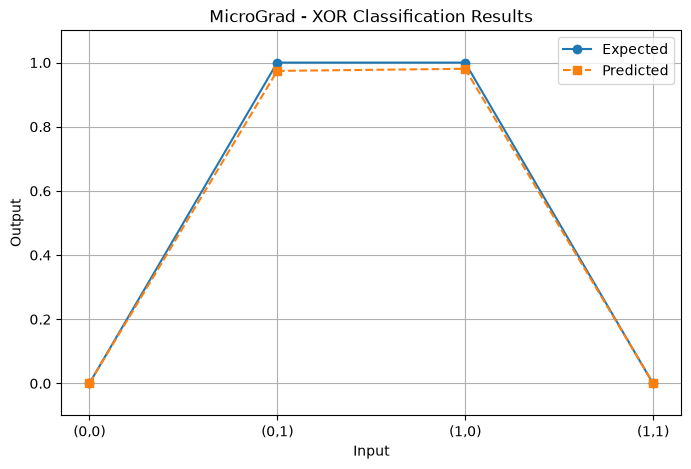

In [10]:
# Visualize the final predictions

predictions = [model(x).data for x in X]

plt.figure(figsize=(8, 5))

plt.plot(range(len(y)), y, "o-", label="Expected")
plt.plot(range(len(y)), predictions, "s--", label="Predicted")

plt.xticks(range(4), ["(0,0)", "(0,1)", "(1,0)", "(1,1)"])
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("MicroGrad - XOR Classification Results")
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# Training loop with loss history

loss_history = []

for epoch in range(epochs):

    # 1. Forward pass
    predictions = [model(x) for x in X]

    # 2. Calculate MSE loss
    loss = sum(
        (prediction - target) ** 2
        for prediction, target in zip(predictions, y)
    ) / len(y)

    # 3. Reset gradients
    model.zero_grad()

    # 4. Backward pass
    loss.backward()

    # 5. Update parameters
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    # 6. Save loss
    loss_history.append(loss.data)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.6f}")

Epoch 0: Loss = 0.000262
Epoch 100: Loss = 0.000254
Epoch 200: Loss = 0.000247
Epoch 300: Loss = 0.000240
Epoch 400: Loss = 0.000234
Epoch 500: Loss = 0.000228
Epoch 600: Loss = 0.000222
Epoch 700: Loss = 0.000216
Epoch 800: Loss = 0.000211
Epoch 900: Loss = 0.000206
Epoch 1000: Loss = 0.000201
Epoch 1100: Loss = 0.000196
Epoch 1200: Loss = 0.000192
Epoch 1300: Loss = 0.000188
Epoch 1400: Loss = 0.000184
Epoch 1500: Loss = 0.000180
Epoch 1600: Loss = 0.000176
Epoch 1700: Loss = 0.000172
Epoch 1800: Loss = 0.000169
Epoch 1900: Loss = 0.000166
Epoch 2000: Loss = 0.000162
Epoch 2100: Loss = 0.000159
Epoch 2200: Loss = 0.000156
Epoch 2300: Loss = 0.000154
Epoch 2400: Loss = 0.000151
Epoch 2500: Loss = 0.000148
Epoch 2600: Loss = 0.000146
Epoch 2700: Loss = 0.000143
Epoch 2800: Loss = 0.000141
Epoch 2900: Loss = 0.000138
Epoch 3000: Loss = 0.000136
Epoch 3100: Loss = 0.000134
Epoch 3200: Loss = 0.000132
Epoch 3300: Loss = 0.000130
Epoch 3400: Loss = 0.000128
Epoch 3500: Loss = 0.000126
Epoc

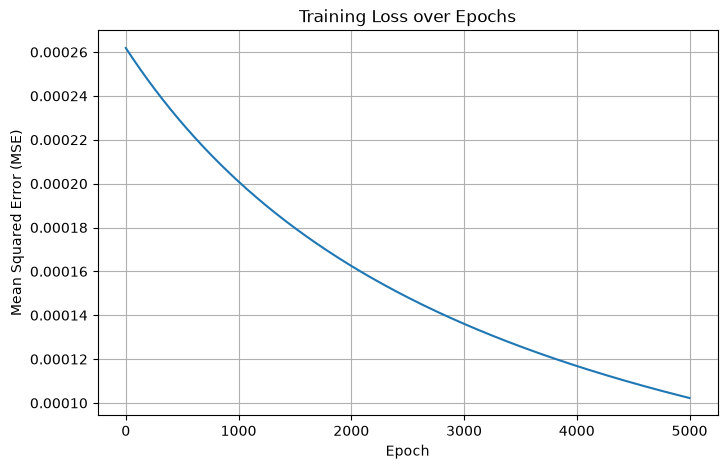

In [12]:
# Visualize training loss

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training Loss over Epochs")

plt.grid(True)
plt.show()